<a href="https://colab.research.google.com/github/shoaibmalik2006/ds311-p12-mobile-money-fraud-miner/blob/salman%2Fweek8-pca-app/04_feature_selection_pca_salman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# P12 · Mobile-Money Fraud Miner — Product Lead Notebook (Week 8)

**Course:** DS-311 Data Mining · BS-AI 2024F, Section A · NBC, NUST · Fall 2026  
**Author:** Salman Hussian (Product lead) · **Group 2:** Shoaib Malik, Uzair Kakar, Salman Hussian  
**Week / milestone:** Week 8 (M2), feature selection and PCA experiment

**What this notebook needs:** `paysim_transfer_cashout.parquet` in Drive `processed/`, `src/features.py` from Uzair's branch (`uzair/week8-features-leakage`) and `src/pipeline.py` and `src/metrics.py` from Shoaib's branch (`shoaib/week8-split-baselines`).

**Goal:** find out **which features matter** and whether **PCA helps** (and where it does not), using the same time split and the same training-set sampling as the rest of the team. Only the **validation** set is used here; the test set is never touched.

---
### Notebook map

| Section | Pipeline stage | Question it answers |
|---|---|---|
| 1. Setup | Reproducibility | Are seeds and versions fixed and recorded? |
| 2. Repo modules and data | Team workflow, Stage 1 | Do the shared `src/` modules and the data load? |
| 3. Features, split, sampling | Stage 4 and 5 | Do we use the same inputs, split and sample as Shoaib? |
| 4. Feature selection | Stage 4: Transform and reduce | Which features matter, and how few do we need? |
| 5. PCA experiment | Stage 4: Transform and reduce | Does PCA keep the fraud signal? |
| 6. Where PCA does not help | Stage 7: Interpret | Which of our four points do the numbers support? |
| 7. Summary | Interpretation | What did we learn, and what are the limits? |

**How to run:** `Runtime > Restart session and run all`. The data cell asks for Google Drive access (click Allow).

## 1. Setup

**Purpose:** make the notebook reproducible: same code, same seed, same results.

**What we did:** imported the libraries, fixed `SEED = 42`, and printed the library versions.

**How to read the output:** one line of versions. No errors are expected.

In [1]:
import os, sys, json, warnings, importlib, subprocess, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.stats import skew
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("Seed:", SEED)

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | scipy 1.16.3 | scikit-learn 1.6.1
Seed: 42


## 2. Repo modules and data

### 2.1 Get the shared modules from the repository

**Purpose:** notebooks do not copy code from each other; shared code lives in `src/` and is imported. Neither Uzair's nor Shoaib's PR is merged yet, so we take their files straight from their branches (the same `fetch` and `checkout FETCH_HEAD` method as in the team handout).

**What we did:** cloned the repository into a folder `repo`, took `src/features.py` from Uzair's branch and `src/pipeline.py` and `src/metrics.py` from Shoaib's branch, and imported them.

**After Wednesday's merge:** set the two `USE_MAIN_...` switches to `True`; the files are then taken from `main`.

**How to read the output:** the listing of `repo/src` should show `features.py`, `pipeline.py` and `metrics.py`. No password or token may be typed into a cell.

In [2]:
REPO_URL      = "https://github.com/shoaibmalik2006/ds311-p12-mobile-money-fraud-miner.git"
UZAIR_BRANCH  = "uzair/week8-features-leakage"
SHOAIB_BRANCH = "shoaib/week8-split-baselines"
USE_MAIN_FOR_FEATURES = False   # set True after Uzair's PR is merged
USE_MAIN_FOR_PIPELINE = False   # set True after Shoaib's PR is merged

def run(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out)
    if r.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}")

run("rm -rf repo")
run(f"git clone -q {REPO_URL} repo")
if not USE_MAIN_FOR_FEATURES:
    run(f"git -C repo fetch -q origin {UZAIR_BRANCH}")
    run("git -C repo checkout FETCH_HEAD -- src/features.py")
if not USE_MAIN_FOR_PIPELINE:
    run(f"git -C repo fetch -q origin {SHOAIB_BRANCH}")
    run("git -C repo checkout FETCH_HEAD -- src/pipeline.py src/metrics.py")

if "repo" not in sys.path:
    sys.path.insert(0, "repo")
from src import features, pipeline, metrics
for m in (features, pipeline, metrics):
    importlib.reload(m)

print("Files in repo/src:", sorted(os.listdir("repo/src")))
print("Imports OK:", features.__name__, pipeline.__name__, metrics.__name__)

Files in repo/src: ['__init__.py', '__pycache__', 'features.py', 'metrics.py', 'pipeline.py']
Imports OK: src.features src.pipeline src.metrics


### 2.2 Load the processed data

**Purpose:** read the file saved at the end of notebook 01 (TRANSFER and CASH_OUT rows only).

**What we did:** mounted Google Drive and read `paysim_transfer_cashout.parquet` from `DS311_P12_Data/processed/` (fallback: the `.csv.gz` version), checked the needed columns and printed the size.

**How to read the output:** one `Finding` line with rows, frauds, fraud rate and step range.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/DS311_P12_Data"
PROC_DIR   = DRIVE_ROOT + "/processed"
parquet_path = PROC_DIR + "/paysim_transfer_cashout.parquet"
csv_path     = PROC_DIR + "/paysim_transfer_cashout.csv.gz"

if os.path.exists(parquet_path):
    df = pd.read_parquet(parquet_path); DATA_FILE = parquet_path
elif os.path.exists(csv_path):
    df = pd.read_csv(csv_path); DATA_FILE = csv_path
else:
    raise FileNotFoundError("Processed file not found. Run notebook 01 (Save cell) first.")

required = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

print("Loaded:", DATA_FILE)
print(f"Finding: {len(df):,} rows, {int(df['isFraud'].sum()):,} frauds = {df['isFraud'].mean():.3%}; "
      f"step runs from {int(df['step'].min())} to {int(df['step'].max())}.")

Mounted at /content/drive
Loaded: /content/drive/MyDrive/DS311_P12_Data/processed/paysim_transfer_cashout.parquet
Finding: 2,770,409 rows, 8,213 frauds = 0.296%; step runs from 1 to 743.


## 3. Features, split and sampling (same set-up as Shoaib)

**Purpose:** everybody must use the same inputs, the same time split and the same sampling, otherwise our numbers cannot be compared.

**What we did:**
- applied Uzair's feature function and took his **full** feature list;
- checked there is no NaN or infinite value in the features;
- split by time with `pipeline.time_split` (train, validation, test) and sampled **only the training set** with `pipeline.sample_training` (all frauds plus 10 % of normal rows, seed 42);
- split the feature list into `type` (one-hot), numeric columns (scaled) and 0/1 flags (passed through).

**Names to confirm with Uzair:** the cell looks for the function and the full list under a few likely names. If it cannot find them it prints the names that exist; then edit the candidate lists.

**How to read the output:** the engineered column names, the three column groups, and one summary table of the three periods. The test set is only counted here, never used.

In [4]:
def pick(module, names, what):
    for n in names:
        if hasattr(module, n):
            return getattr(module, n), n
    public = [n for n in dir(module) if not n.startswith("_")]
    raise AttributeError(f"No {what} found in src/features.py. Names that exist: {public}. Edit the candidate list.")

FUNC_NAMES = ["add_features", "engineer_features", "build_features", "make_features", "add_engineered_features"]
FULL_NAMES = ["FULL", "FULL_FEATURES", "full", "full_features", "FEATURES_FULL"]

feature_fn, fn_name = pick(features, FUNC_NAMES, "feature function")
FULL_FEATURES, full_name = pick(features, FULL_NAMES, "full feature list")
FULL_FEATURES = list(FULL_FEATURES)

cols_before = set(df.columns)
tmp = df.copy()
res = feature_fn(tmp)
df = tmp if res is None else res
new_cols = [c for c in df.columns if c not in cols_before]
print(f"Using features.{fn_name}(), features.{full_name} ({len(FULL_FEATURES)} columns)")
print("New columns created by the function:", new_cols)

if "type" not in FULL_FEATURES:
    FULL_FEATURES = ["type"] + FULL_FEATURES
missing = [c for c in FULL_FEATURES if c not in df.columns]
assert not missing, f"Feature columns missing: {missing}"

num_check = df[[c for c in FULL_FEATURES if c != "type"]]
n_nan = int(num_check.isna().sum().sum())
n_inf = int(np.isinf(num_check.to_numpy(dtype="float64")).sum())
assert n_nan == 0 and n_inf == 0, "Fix the feature function before continuing."

# same time split and the same training sample as Shoaib
TRAIN_END, VAL_END = pipeline.TRAIN_END, pipeline.VAL_END
train, val, test = pipeline.time_split(df, TRAIN_END, VAL_END)
train_s = pipeline.sample_training(train, frac_normal=0.10, seed=SEED)
display(pipeline.split_summary(train, val, test))

CAT_COLS = ["type"]
rest = [c for c in FULL_FEATURES if c not in CAT_COLS]
FLAG_COLS = [c for c in rest if set(df[c].dropna().unique()) <= {0, 1}]
NUM_COLS  = [c for c in rest if c not in FLAG_COLS]
print("Categorical (one-hot):", CAT_COLS)
print("Numeric (scaled):     ", NUM_COLS)
print("Flags (passed through):", FLAG_COLS)

def make_xy(part):
    X = part[FULL_FEATURES].copy()
    X["type"] = X["type"].astype(str)
    return X, part["isFraud"].astype(int).to_numpy()

X_train, y_train = make_xy(train_s)
X_val,   y_val   = make_xy(val)
print(f"Finding: {len(FULL_FEATURES)} inputs; training sample {len(train_s):,} rows ({y_train.mean():.2%} fraud); "
      f"validation {len(val):,} rows ({y_val.mean():.3%} fraud, natural rate). Test set not used.")

Using features.add_features(), features.FULL_FEATURES (13 columns)
New columns created by the function: ['type_is_transfer', 'errorBalanceOrig', 'errorBalanceDest', 'origEmptied', 'destZeroBefore', 'origBalanceZero', 'amountToBalanceRatio']


,period,step_min,step_max,rows,frauds,fraud_rate_%
0,train,1,500,2645779,5561,0.2102
1,validation,501,600,81080,1052,1.2975
2,test,601,743,43550,1600,3.6739


Categorical (one-hot): ['type']
Numeric (scaled):      ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'hour', 'amountToBalanceRatio', 'newbalanceOrig', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest']
Flags (passed through): ['type_is_transfer', 'destZeroBefore', 'origBalanceZero', 'origEmptied']
Finding: 14 inputs; training sample 269,583 rows (2.06% fraud); validation 81,080 rows (1.297% fraud, natural rate). Test set not used.


### 3.1 Preprocess (fitted on training data only)

**Purpose:** feature selection and PCA both need numbers, so we encode `type` and scale the numeric columns. As in Shoaib's Pipeline, the encoder and scaler are **fitted on the training sample only** and then applied to validation.

**What we did:** built a `ColumnTransformer` with the same three groups (`cat`, `num`, `flags`) as the shared Pipeline, fitted it on the sampled training set, and transformed training and validation.

**How to read the output:** the names of the model-ready columns and the matrix shapes.

In [5]:
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # older scikit-learn
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

prep = ColumnTransformer(
    [("cat", ohe, CAT_COLS), ("num", StandardScaler(), NUM_COLS), ("flags", "passthrough", FLAG_COLS)],
    sparse_threshold=0)
Xt_train = prep.fit_transform(X_train)
Xt_val   = prep.transform(X_val)
names = list(prep.get_feature_names_out())
short = [n.split("__", 1)[1] for n in names]
print("Model-ready columns:", short)
print(f"Finding: training matrix {Xt_train.shape}, validation matrix {Xt_val.shape}.")

Model-ready columns: ['type_CASH_OUT', 'type_TRANSFER', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'hour', 'amountToBalanceRatio', 'newbalanceOrig', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest', 'type_is_transfer', 'destZeroBefore', 'origBalanceZero', 'origEmptied']
Finding: training matrix (269583, 15), validation matrix (81080, 15).


## 4. Feature selection

### 4.1 Correlation heatmap

**Purpose:** see which numeric features carry the same information. Strongly correlated features are redundant, and the correlation with `isFraud` gives a first hint of which ones matter.

**What we did:** computed the Pearson correlation between the numeric features (and `isFraud`) on the sampled training set and drew it as a heatmap.

**How to read the output:** red is a strong positive correlation, blue a strong negative one. Look for blocks of features that move together (for example old and new balances) and for the last row/column (`isFraud`).

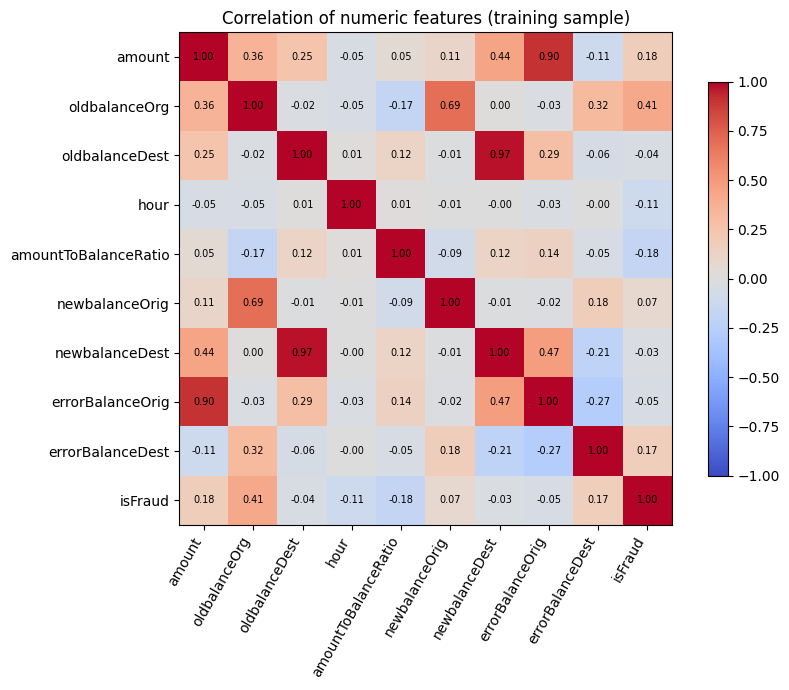

Finding: the most correlated pair of features is oldbalanceDest and newbalanceDest (r = 0.97); the feature most correlated with isFraud is oldbalanceOrg (|r| = 0.41).


In [6]:
corr_cols = NUM_COLS + ["isFraud"]
corr = train_s[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation of numeric features (training sample)")
plt.tight_layout(); plt.show()

pairs = corr.drop(index="isFraud", columns="isFraud").where(np.triu(np.ones((len(NUM_COLS),) * 2), k=1).astype(bool)).stack()
top_pair = pairs.abs().sort_values(ascending=False).index[0]
fraud_corr = corr["isFraud"].drop("isFraud").abs().sort_values(ascending=False)
print(f"Finding: the most correlated pair of features is {top_pair[0]} and {top_pair[1]} (r = {pairs[top_pair]:.2f}); "
      f"the feature most correlated with isFraud is {fraud_corr.index[0]} (|r| = {fraud_corr.iloc[0]:.2f}).")

### 4.2 Mutual information and decision-tree importance

**Purpose:** rank **all** model inputs (including `type` and the flags) by how much they tell us about fraud, with two different methods so that one method's weakness does not decide alone.

**What we did:**
- **Mutual information** (`mutual_info_classif`): how much knowing the feature reduces uncertainty about `isFraud`. It also catches non-linear links. It runs on a random sample of at most 100,000 training rows for speed.
- **Decision-tree importance:** a tree (`max_depth = 8`, `min_samples_leaf = 20`) is fitted on the training sample; the importance is how much each feature reduced impurity.
- Both are turned into ranks (1 = best) and averaged into one **mean rank**.

**How to read the output:** the table is sorted by mean rank (best first); the bar charts show the two scores. Features at the top are our "top 3" and "top 5". Remember that post-transaction balances are expected near the top (the realism gap of RQ2).

,feature,mutual_info,tree_importance,rank_mi,rank_tree,mean_rank
0,newbalanceDest,0.0360,0.3441,4.0000,1.0000,2.5000
1,oldbalanceOrg,0.0467,0.1266,3.0000,4.0000,3.5000
2,errorBalanceOrig,0.0470,0.0626,2.0000,5.0000,3.5000
3,hour,0.0248,0.0346,6.0000,7.0000,6.5000
4,origEmptied,0.0147,0.0404,8.0000,6.0000,7.0000
5,errorBalanceDest,0.0278,0.0004,5.0000,9.0000,7.0000
6,amountToBalanceRatio,0.1016,0.0000,1.0000,13.5000,7.2500
7,type_TRANSFER,0.0051,0.1288,13.0000,3.0000,8.0000
8,newbalanceOrig,0.0042,0.2440,15.0000,2.0000,8.5000
9,destZeroBefore,0.0139,0.0185,10.0000,8.0000,9.0000


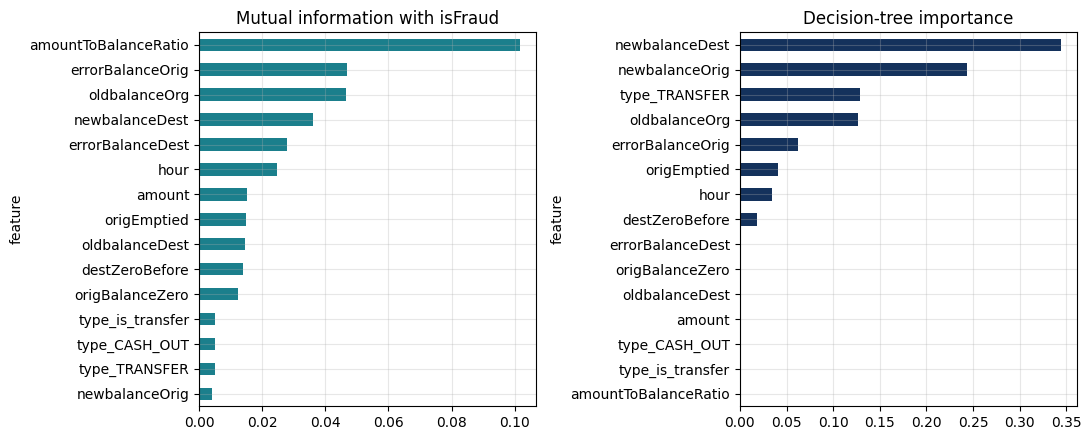

Finding: top 5 by mean rank = ['newbalanceDest', 'oldbalanceOrg', 'errorBalanceOrig', 'hour', 'origEmptied'].


In [7]:
rng = np.random.RandomState(SEED)
sub = rng.choice(len(Xt_train), size=min(100_000, len(Xt_train)), replace=False)
discrete_mask = np.array([n.startswith("cat__") or n.startswith("flags__") for n in names])

mi = mutual_info_classif(Xt_train[sub], y_train[sub], discrete_features=discrete_mask, random_state=SEED)

TREE_PARAMS = dict(max_depth=8, min_samples_leaf=20, random_state=SEED)
imp_tree = DecisionTreeClassifier(**TREE_PARAMS).fit(Xt_train, y_train)

fs = pd.DataFrame({"feature": short, "mutual_info": mi, "tree_importance": imp_tree.feature_importances_})
fs["rank_mi"] = fs["mutual_info"].rank(ascending=False)
fs["rank_tree"] = fs["tree_importance"].rank(ascending=False)
fs["mean_rank"] = (fs["rank_mi"] + fs["rank_tree"]) / 2
fs = fs.sort_values(["mean_rank", "tree_importance"], ascending=[True, False]).reset_index(drop=True)
display(fs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fs.sort_values("mutual_info").plot.barh(x="feature", y="mutual_info", ax=axes[0], color="#1B7F8C", legend=False)
axes[0].set_title("Mutual information with isFraud")
fs.sort_values("tree_importance").plot.barh(x="feature", y="tree_importance", ax=axes[1], color="#14325C", legend=False)
axes[1].set_title("Decision-tree importance")
plt.tight_layout(); plt.show()

RANKED = fs["feature"].tolist()
print(f"Finding: top 5 by mean rank = {RANKED[:5]}.")

### 4.3 Does a smaller feature set lose accuracy of detection?

**Purpose:** answer "how many features do we really need?" with the metric that matters, **validation PR-AUC** (never accuracy).

**What we did:** trained the same decision tree (same settings as in 4.2) on the **top 3**, **top 5** and **all** features from the ranking above, always fitted on the sampled training set and scored on the validation set at its natural fraud rate. *(Optional: replace `TREE_PARAMS` by the settings Shoaib chose in his notebook.)*

**How to read the output:** a table with one row per feature set and a bar chart. If the top 3 or top 5 reach almost the same PR-AUC as all features, the extra features add little. The `Finding` line states the numbers.

,feature set,n_features,val PR-AUC,features
0,Top 3,3,0.7833,"newbalanceDest, oldbalanceOrg, errorBalanceOrig"
1,Top 5,5,0.9991,"newbalanceDest, oldbalanceOrg, errorBalanceOrig, hour, origEmptied"
2,All (15),15,1.0000,"newbalanceDest, oldbalanceOrg, errorBalanceOrig, hour, origEmptied, errorBalanceDest, amountToBalanceRatio, type_TRANSFER, newbalanceOrig, destZeroBefore, oldbalanceDest, amount, origBalanceZero, type_CASH_OUT, type_is_transfer"


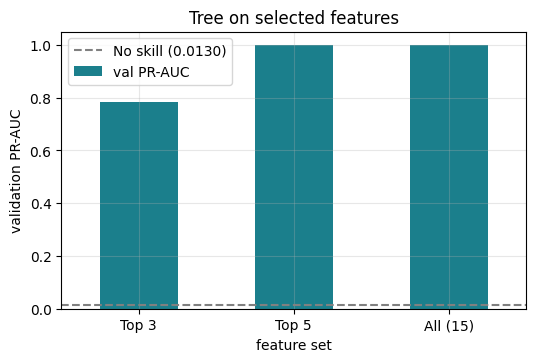

Finding: validation PR-AUC is 0.7833 with the top 3, 0.9991 with the top 5 and 1.0000 with all 15 features.


In [8]:
def val_pr_auc(cols, params=TREE_PARAMS):
    idx = [short.index(c) for c in cols]
    t = DecisionTreeClassifier(**params).fit(Xt_train[:, idx], y_train)
    return metrics.pr_auc(y_val, t.predict_proba(Xt_val[:, idx])[:, 1])

sel_rows = []
for label, cols in [("Top 3", RANKED[:3]), ("Top 5", RANKED[:5]), (f"All ({len(RANKED)})", RANKED)]:
    sel_rows.append({"feature set": label, "n_features": len(cols), "val PR-AUC": val_pr_auc(cols), "features": ", ".join(cols)})
sel_table = pd.DataFrame(sel_rows)
display(sel_table)

fig, ax = plt.subplots(figsize=(6, 3.6))
sel_table.plot.bar(x="feature set", y="val PR-AUC", ax=ax, color="#1B7F8C", legend=False)
ax.axhline(y_val.mean(), color="grey", linestyle="--", label=f"No skill ({y_val.mean():.4f})"); ax.legend()
ax.set_ylabel("validation PR-AUC"); ax.set_title("Tree on selected features"); plt.xticks(rotation=0); plt.show()

p3, p5, pall = sel_table["val PR-AUC"].tolist()
print(f"Finding: validation PR-AUC is {p3:.4f} with the top 3, {p5:.4f} with the top 5 and {pall:.4f} with all {len(RANKED)} features.")

## 5. PCA experiment

### 5.1 Fit PCA and look at the explained variance

**Purpose:** test whether compressing the numeric features into a few principal components keeps what is needed to find fraud.

**What we did:** fitted `PCA` on the **scaled numeric features of the sampled training set** (the scaling is already done in the preprocessing above; PCA is fitted on training data only). We plotted the **share of variance explained by each component** and the cumulative share.

**Why numeric features only:** PCA works on continuous values; flags and the one-hot `type` columns are not suited to it, so the fair comparison in 5.2 uses the numeric features only.

**How to read the output:** bars = variance of each component, line = running total. A steep first bar means a few directions carry most of the *variance*. That is **not** the same as carrying the *fraud signal*; section 5.2 tests that.

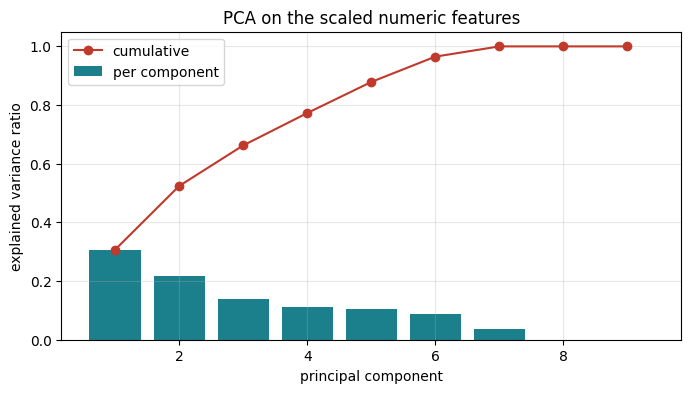

Finding: PC1 explains 30.7% of the variance, the first 2 explain 52.4%, and 6 of 9 components are needed for 95%.


In [9]:
num_idx = [short.index(c) for c in NUM_COLS]
Xn_train, Xn_val = Xt_train[:, num_idx], Xt_val[:, num_idx]

pca = PCA(random_state=SEED).fit(Xn_train)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

fig, ax = plt.subplots()
ax.bar(range(1, len(evr) + 1), evr, color="#1B7F8C", label="per component")
ax.plot(range(1, len(evr) + 1), cum, marker="o", color="#C0392B", label="cumulative")
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance ratio"); ax.set_ylim(0, 1.05)
ax.set_title("PCA on the scaled numeric features"); ax.legend(); plt.show()

n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Finding: PC1 explains {evr[0]:.1%} of the variance, the first 2 explain {cum[1]:.1%}, and {n95} of {len(evr)} components are needed for 95%.")

### 5.2 Tree on 2, 3, 5 and all components versus the raw features

**Purpose:** the real test. If PCA keeps the fraud signal, a tree on a few components should score about the same as a tree on the raw features.

**What we did:** trained the same tree on (a) the first 2, 3, 5 and all components and (b) the **raw numeric features**, and also (c) **all raw inputs** (numeric + flags + `type`) for reference. Everything is fitted on the sampled training set and scored on the validation set (natural rate) with PR-AUC.

**How to read the output:** compare each PCA row with the raw numeric row. "All components" contains the same information as the raw numeric features, only rotated, so a gap there is due to how trees split on rotated axes.

,input,n_inputs,val PR-AUC
0,"PCA, 2 components",2,0.4416
1,"PCA, 3 components",3,0.5922
2,"PCA, 5 components",5,0.6563
3,"PCA, 9 components (all)",9,0.8060
4,Raw numeric features,9,1.0000
5,All raw inputs (numeric + flags + type),15,1.0000


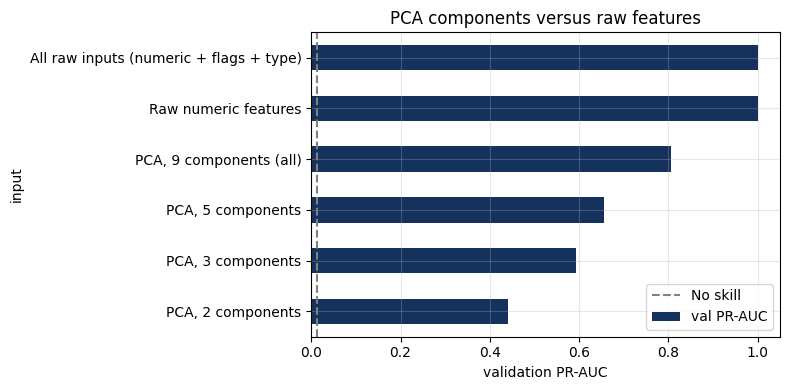

Finding: validation PR-AUC is 0.4416 with 2 components, 0.8060 with all components and 1.0000 with the raw numeric features.


In [10]:
Z_train, Z_val = pca.transform(Xn_train), pca.transform(Xn_val)

def tree_pr(Xtr, Xva, params=TREE_PARAMS):
    t = DecisionTreeClassifier(**params).fit(Xtr, y_train)
    return metrics.pr_auc(y_val, t.predict_proba(Xva)[:, 1])

n_num = len(NUM_COLS)
ks = sorted({k for k in (2, 3, 5) if k < n_num} | {n_num})
pca_rows = [{"input": f"PCA, {k} components" + (" (all)" if k == n_num else ""), "n_inputs": k,
             "val PR-AUC": tree_pr(Z_train[:, :k], Z_val[:, :k])} for k in ks]
pca_rows.append({"input": "Raw numeric features", "n_inputs": n_num, "val PR-AUC": tree_pr(Xn_train, Xn_val)})
pca_rows.append({"input": "All raw inputs (numeric + flags + type)", "n_inputs": len(short), "val PR-AUC": tree_pr(Xt_train, Xt_val)})
pca_table = pd.DataFrame(pca_rows)
display(pca_table)

fig, ax = plt.subplots(figsize=(8, 4))
pca_table.plot.barh(x="input", y="val PR-AUC", ax=ax, color="#14325C", legend=False)
ax.axvline(y_val.mean(), color="grey", linestyle="--", label="No skill"); ax.legend()
ax.set_xlabel("validation PR-AUC"); ax.set_title("PCA components versus raw features"); plt.tight_layout(); plt.show()

raw_num = pca_table.loc[pca_table["input"] == "Raw numeric features", "val PR-AUC"].iloc[0]
pca2 = pca_table.iloc[0]["val PR-AUC"]
pca_all = pca_table.loc[pca_table["n_inputs"] == n_num].iloc[0]["val PR-AUC"]
print(f"Finding: validation PR-AUC is {pca2:.4f} with 2 components, {pca_all:.4f} with all components and {raw_num:.4f} with the raw numeric features.")

### 5.3 The first two components, coloured by fraud and normal

**Purpose:** see with our own eyes whether fraud separates from normal in the plane of the first two components.

**What we did:** drew PC1 against PC2 for a sample of the training set: **all frauds (up to 2,000)** and **5,000 normal rows**, with fraud in red and normal in blue. Axes are clipped to the 1st–99th percentile so a few extreme points do not squash the picture.

**How to read the output:** if the red points sit inside the blue cloud, PCA does not separate the classes. Separate red clusters would mean the opposite.

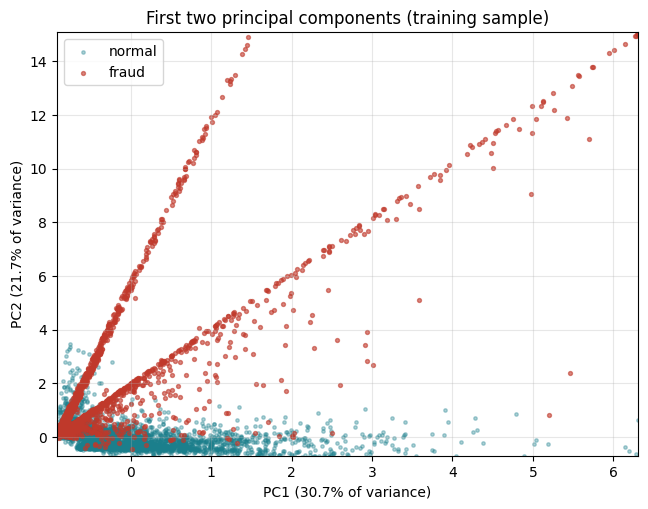

Finding: mean position of fraud is (PC1 -0.00, PC2 3.15) and of normal rows (PC1 0.00, PC2 -0.07); judge from the picture how much the two clouds overlap.


In [11]:
rng = np.random.RandomState(SEED)
fraud_idx  = np.where(y_train == 1)[0]
normal_idx = np.where(y_train == 0)[0]
fraud_pick  = rng.choice(fraud_idx,  size=min(2000, len(fraud_idx)),  replace=False)
normal_pick = rng.choice(normal_idx, size=min(5000, len(normal_idx)), replace=False)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(Z_train[normal_pick, 0], Z_train[normal_pick, 1], s=6, alpha=0.35, color="#1B7F8C", label="normal")
ax.scatter(Z_train[fraud_pick, 0],  Z_train[fraud_pick, 1],  s=8, alpha=0.6,  color="#C0392B", label="fraud")
pts = np.vstack([Z_train[normal_pick, :2], Z_train[fraud_pick, :2]])
lo, hi = np.percentile(pts, 1, axis=0), np.percentile(pts, 99, axis=0)
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
ax.set_xlabel(f"PC1 ({evr[0]:.1%} of variance)"); ax.set_ylabel(f"PC2 ({evr[1]:.1%} of variance)")
ax.set_title("First two principal components (training sample)"); ax.legend(); plt.show()

f_mean, n_mean = Z_train[fraud_idx, :2].mean(axis=0), Z_train[normal_idx, :2].mean(axis=0)
print(f"Finding: mean position of fraud is (PC1 {f_mean[0]:.2f}, PC2 {f_mean[1]:.2f}) and of normal rows (PC1 {n_mean[0]:.2f}, PC2 {n_mean[1]:.2f}); "
      f"judge from the picture how much the two clouds overlap.")

## 6. Where PCA does not help: checking each point against our numbers

**Purpose:** the team handout lists four reasons why PCA may not help for fraud. We do not repeat them from theory; we **check each one against the numbers above** and say which ones our results support.

**What we did:** one code cell computes the evidence for each point and prints "supported" or "not supported" from the variables (nothing typed by hand):
1. **PCA keeps variance, not class separation:** is the component with the highest mutual information with fraud also the one with the most variance (PC1)?
2. **Fraud lives in rare combinations (balance patterns and flags):** does a tree on few components score clearly below the raw features, and do the flags add something on top of the numeric features?
3. **Heavy-tailed amounts dominate the components:** are the numeric features strongly skewed, and is PC1 built mainly from one or two of them?
4. **Interpretability is lost:** how many original features does each component mix?

**How to read the output:** four blocks, each with the numbers it is based on. The markdown cell after it is for **your own** wording of the note, written after you have read the numbers.

In [12]:
SUPPORT = {}

# 1. variance vs class separation
mi_pc = mutual_info_classif(Z_train[sub], y_train[sub], random_state=SEED)
best_pc = int(np.argmax(mi_pc)) + 1
SUPPORT[1] = best_pc != 1
print("POINT 1 - PCA keeps variance, not class separation")
print(pd.DataFrame({"component": [f"PC{i+1}" for i in range(len(evr))], "variance share": evr, "mutual info with fraud": mi_pc}).head(6).to_string(index=False))
print(f"  -> PC1 has the most variance ({evr[0]:.1%}); the component most linked to fraud is PC{best_pc}. "
      f"{'SUPPORTED' if SUPPORT[1] else 'NOT supported'} by our numbers.\n")

# 2. rare combinations
all_raw = pca_table.loc[pca_table["input"].str.startswith("All raw"), "val PR-AUC"].iloc[0]
SUPPORT[2] = (pca2 < raw_num - 0.02)
print("POINT 2 - fraud lives in rare combinations (balance patterns, flags)")
print(f"  -> 2 components: {pca2:.4f} | all components: {pca_all:.4f} | raw numeric: {raw_num:.4f} | all raw inputs: {all_raw:.4f}")
print(f"  -> {'SUPPORTED' if SUPPORT[2] else 'NOT supported'}: 2 components score {raw_num - pca2:+.4f} below the raw numeric features "
      f"(threshold used: 0.02); adding flags and type changes PR-AUC by {all_raw - raw_num:+.4f}.\n")

# 3. heavy tails
sk = pd.Series(skew(train_s[NUM_COLS].to_numpy(dtype="float64"), axis=0), index=NUM_COLS).sort_values(key=np.abs, ascending=False)
load = pd.Series(pca.components_[0], index=NUM_COLS)
top2_share = float((load ** 2).sort_values(ascending=False).iloc[:2].sum())
SUPPORT[3] = bool(sk.abs().max() > 5 and top2_share > 0.5)
print("POINT 3 - heavy-tailed amounts dominate the components")
print("  skewness of numeric features (|skew| > 5 is very heavy-tailed):")
print(sk.round(2).to_string())
print(f"  -> the two biggest loadings make up {top2_share:.0%} of PC1; largest |skew| = {sk.abs().max():.1f}. "
      f"{'SUPPORTED' if SUPPORT[3] else 'NOT supported'} by our numbers.\n")

# 4. interpretability
mix = [(int((np.abs(pca.components_[i]) > 0.2).sum())) for i in range(min(5, len(evr)))]
SUPPORT[4] = max(mix) >= 3
print("POINT 4 - interpretability for analysts is lost")
print(f"  -> number of original features with a loading above 0.2 in PC1..PC{len(mix)}: {mix} (of {len(NUM_COLS)}).")
print(f"  -> {'SUPPORTED' if SUPPORT[4] else 'NOT supported'}: a component mixes several balances and amounts, so an analyst cannot read a single rule from it.")
print("\nPC1 loadings (what PC1 is made of):")
display(load.sort_values(key=np.abs, ascending=False).to_frame("PC1 loading"))
print("Finding: points supported by our numbers: " + (", ".join(str(k) for k, v in SUPPORT.items() if v) or "none") +
      "; not supported: " + (", ".join(str(k) for k, v in SUPPORT.items() if not v) or "none") + ".")

POINT 1 - PCA keeps variance, not class separation
component  variance share  mutual info with fraud
      PC1          0.3069                  0.0068
      PC2          0.2172                  0.0376
      PC3          0.1383                  0.0041
      PC4          0.1104                  0.0243
      PC5          0.1060                  0.0182
      PC6          0.0864                  0.0246
  -> PC1 has the most variance (30.7%); the component most linked to fraud is PC2. SUPPORTED by our numbers.

POINT 2 - fraud lives in rare combinations (balance patterns, flags)
  -> 2 components: 0.4416 | all components: 0.8060 | raw numeric: 1.0000 | all raw inputs: 1.0000
  -> SUPPORTED: 2 components score +0.5584 below the raw numeric features (threshold used: 0.02); adding flags and type changes PR-AUC by +0.0000.

POINT 3 - heavy-tailed amounts dominate the components
  skewness of numeric features (|skew| > 5 is very heavy-tailed):
newbalanceOrig          94.4300
oldbalanceOrg        

,PC1 loading
newbalanceDest,0.5292
errorBalanceOrig,0.4938
amount,0.4739
oldbalanceDest,0.4511
errorBalanceDest,-0.1769
amountToBalanceRatio,0.1190
oldbalanceOrg,0.0452
hour,-0.0219
newbalanceOrig,0.0117


Finding: points supported by our numbers: 1, 2, 3, 4; not supported: none.


### Note: where PCA does not help (write this in your own words after reading the output above)

*Replace this text. Keep it short (5 to 8 lines). For each of the four points say whether **our numbers** support it, and quote the number (for example the PR-AUC with 2 components versus the raw features). If a point is **not** supported, say so honestly; that is a valid result.*

- **Variance, not class separation:** ...
- **Rare combinations (balance patterns, flags):** ...
- **Heavy-tailed amounts dominate:** ...
- **Interpretability:** ...
- **Conclusion for our project:** ... (for example: we keep the raw engineered features, and use PCA only for the 2-D picture.)

## 7. Summary and limitations

**Purpose:** print the key findings from variables (nothing typed by hand) so the numbers always match the run. The last line is the **Key result** for the pull request.

**How to read the output:** one block of lines in the order of the notebook.

In [13]:
print("SUMMARY OF WEEK 8 (Salman: feature selection and PCA; all numbers come from this run)")
print("-" * 70)
print(f"Data: {len(df):,} rows (TRANSFER and CASH_OUT); training sample {len(train_s):,} rows, validation {len(val):,} rows. Test set not used.")
print(f"Most correlated feature with isFraud: {fraud_corr.index[0]} (|r| = {fraud_corr.iloc[0]:.2f}).")
print(f"Top 5 features (mean rank of mutual information and tree importance): {RANKED[:5]}.")
print(f"Tree validation PR-AUC: top 3 = {p3:.4f}, top 5 = {p5:.4f}, all {len(RANKED)} = {pall:.4f}.")
print(f"PCA: PC1 explains {evr[0]:.1%}; {n95} of {len(evr)} components needed for 95% of the variance.")
print(f"Tree validation PR-AUC: PCA 2 components = {pca2:.4f}, PCA all components = {pca_all:.4f}, raw numeric = {raw_num:.4f}, all raw inputs = {all_raw:.4f}.")
print("PCA points supported by our numbers:", [k for k, v in SUPPORT.items() if v], "| not supported:", [k for k, v in SUPPORT.items() if not v])
print("-" * 70)
print(f"KEY RESULT FOR THE PR: validation PR-AUC {raw_num:.3f} with raw numeric features vs {pca2:.3f} with 2 PCA components (and {pca_all:.3f} with all components).")

SUMMARY OF WEEK 8 (Salman: feature selection and PCA; all numbers come from this run)
----------------------------------------------------------------------
Data: 2,770,409 rows (TRANSFER and CASH_OUT); training sample 269,583 rows, validation 81,080 rows. Test set not used.
Most correlated feature with isFraud: oldbalanceOrg (|r| = 0.41).
Top 5 features (mean rank of mutual information and tree importance): ['newbalanceDest', 'oldbalanceOrg', 'errorBalanceOrig', 'hour', 'origEmptied'].
Tree validation PR-AUC: top 3 = 0.7833, top 5 = 0.9991, all 15 = 1.0000.
PCA: PC1 explains 30.7%; 6 of 9 components needed for 95% of the variance.
Tree validation PR-AUC: PCA 2 components = 0.4416, PCA all components = 0.8060, raw numeric = 1.0000, all raw inputs = 1.0000.
PCA points supported by our numbers: [1, 2, 3, 4] | not supported: []
----------------------------------------------------------------------
KEY RESULT FOR THE PR: validation PR-AUC 1.000 with raw numeric features vs 0.442 with 2 PCA

### Limitations

- **Validation only.** All scores come from the validation period (natural fraud rate); the test set is reserved for the final comparison.
- **One tree, one seed, fixed settings.** Rankings and PR-AUC may shift slightly with other settings or seeds.
- **Post-transaction balances.** The *full* feature list includes balances recorded after the transaction, so they are expected to rank high; a live system would not have them. Week 13 measures this realism gap (RQ2).
- **Mutual information on a sample.** For speed, mutual information uses at most 100,000 training rows.
- **PCA on numeric features only.** Flags and `type` are not suited to PCA, so the comparison uses the numeric features.
- **Synthetic data.** PaySim is a simulation; feature rankings may differ on real wallet data.